# OLIST E-COMMERCE DATASET - Dataset Visualisation
## Week 1 : Data Science Internship
### Objective : This section presents visual insights from the Olist E-commerce dataset. Charts are used to analyse sales trends, product performance, customer purchasing behaviour, regional revenue, and delivery performance.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Set visualization style
sns.set_theme(style="whitegrid")

# Display charts inside the notebook
%matplotlib inline

print("Visualization libraries imported successfully!")


Visualization libraries imported successfully!


In [3]:
from pathlib import Path

OUTPUT_DIR = Path("outputs") / "charts"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Charts will be saved to: {OUTPUT_DIR.resolve()}")

Charts will be saved to: G:\My Drive\data_science_week1_assignment\02_notebooks\outputs\charts


In [4]:
from pathlib import Path 
from zipfile import ZipFile
from datetime import datetime, timedelta

DATA_DIR = Path("G:\\My Drive\\data_science_week1_assignment\\01_data\\02_cleaned_data")

orders = pd.read_csv(
    DATA_DIR/"orders.csv",
    parse_dates=[
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"

    ]
)

order_items = pd.read_csv(DATA_DIR / "order_items.csv")
order_payments = pd.read_csv(DATA_DIR / "order_payments.csv")
order_reviews = pd.read_csv(DATA_DIR / "order_reviews.csv")
products = pd.read_csv(DATA_DIR / "products.csv")
customers = pd.read_csv(DATA_DIR / "customers.csv")
sellers = pd.read_csv(DATA_DIR / "sellers.csv")
category_translation = pd.read_csv(
    DATA_DIR / "product_category_name_translation.csv"
)

print("Datasets loaded successfully!")
print("Orders:", orders.shape)
print("Order items:", order_items.shape)

Datasets loaded successfully!
Orders: (99441, 8)
Order items: (112650, 7)


In [5]:
# select delivered orders for the initial completed-sales analysis

delivered_orders = orders[
    orders["order_status"] == "delivered"
].copy()

print("Total orders in dataset:", orders["order_id"].nunique())
print("Delivered orders:", delivered_orders["order_id"].nunique())

Total orders in dataset: 99441
Delivered orders: 96478


In [6]:
# Keeping items belonging to delivered orders

delivered_items = order_items.merge(
    delivered_orders[["order_id"]],
    on="order_id",
    how="inner",
    validate="many_to_one"
)

print("Delivered order items:", len(delivered_items))

Delivered order items: 110197


In [7]:
total_revenue = delivered_items["price"].sum()

total_orders = delivered_orders["order_id"].nunique()

average_order_value = (
    total_revenue / total_orders
    if total_orders > 0
    else 0
)

total_units_sold = delivered_items["order_item_id"].count()

kpi_summary = pd.DataFrame({
    "KPI":[
        "Total Revenue",
        "Total Orders",
        "Average Order Value",
        "Total Units Sold"
    ],
    "Value":[
        total_revenue,
        total_orders,
        average_order_value,
        total_units_sold
    ]
})

In [8]:
# Adding english category names to product records

products_eng = products.merge(
    category_translation,
    on="product_category_name",
    how="left",
    validate="many_to_one"
)

products_eng["category_name_english"] = (
    products_eng["product_category_name_english"]
    .fillna("Unknown/Untranslated")
)

# Attaching product and category information to delivered items

sales_items = delivered_items.merge(
    products_eng[
        ["product_id","category_name_english"]
    ],
    on="product_id",
    how="left",
    validate="many_to_one"
)

sales_items["category_name_english"] = (
    sales_items["category_name_english"]
    .fillna("Unknown / Untranslated")
)

print("Sales item rows:", len(sales_items))

Sales item rows: 110197


In [9]:
# Top revenue-generating category

category_sales = (
    sales_items.groupby("category_name_english")
    .agg(
        total_revenue=("price", "sum"),
        units_sold=("order_item_id", "count"),
        unique_orders=("order_id", "nunique")
    )
    .sort_values("total_revenue",ascending=False)
    .reset_index()
)

display(category_sales.head(10))

,category_name_english,total_revenue,units_sold,unique_orders
0,health_beauty,1233131.72,9465,8647
1,watches_gifts,1166176.98,5859,5495
2,bed_bath_table,1023434.76,10953,9272
3,sports_leisure,954852.55,8431,7530
4,computers_accessories,888724.61,7644,6530
5,furniture_decor,711927.69,8160,6307
6,housewares,615628.69,6795,5743
7,cool_stuff,610204.10,3718,3559
8,auto,578966.65,4140,3810
9,toys,471286.48,4030,3804


In [10]:
# Top revenue-generating product

product_sales = (
    sales_items.groupby("product_id")
    .agg(
        total_revenue=("price", "sum"),
        units_sold=("order_item_id", "count"),
        unique_orders=("order_id", "nunique")
    )
    .sort_values("total_revenue", ascending=False)
    .reset_index()
)

display(product_sales.head(10))

,product_id,total_revenue,units_sold,unique_orders
0,bb50f2e236e5eea0100680137654686c,63560.00,194,186
1,6cdd53843498f92890544667809f1595,53652.30,153,148
2,d6160fb7873f184099d9bc95e30376af,45949.35,33,33
3,d1c427060a0f73f6b889a5c7c61f2ac4,45620.56,332,313
4,99a4788cb24856965c36a24e339b6058,42049.66,477,456
5,3dd2a17168ec895c781a9191c1e95ad7,40782.80,272,253
6,25c38557cf793876c5abdd5931f922db,38907.32,38,38
7,5f504b3a1c75b73d6151be81eb05bdc9,37733.90,63,63
8,53b36df67ebb7c41585e8d54d6772e08,37454.63,321,304
9,aca2eb7d00ea1a7b8ebd4e68314663af,37104.30,520,425


### 1. KPI Cards

Chart saved: G:\My Drive\data_science_week1_assignment\03_outputs\charts\01_kpi_cards.png


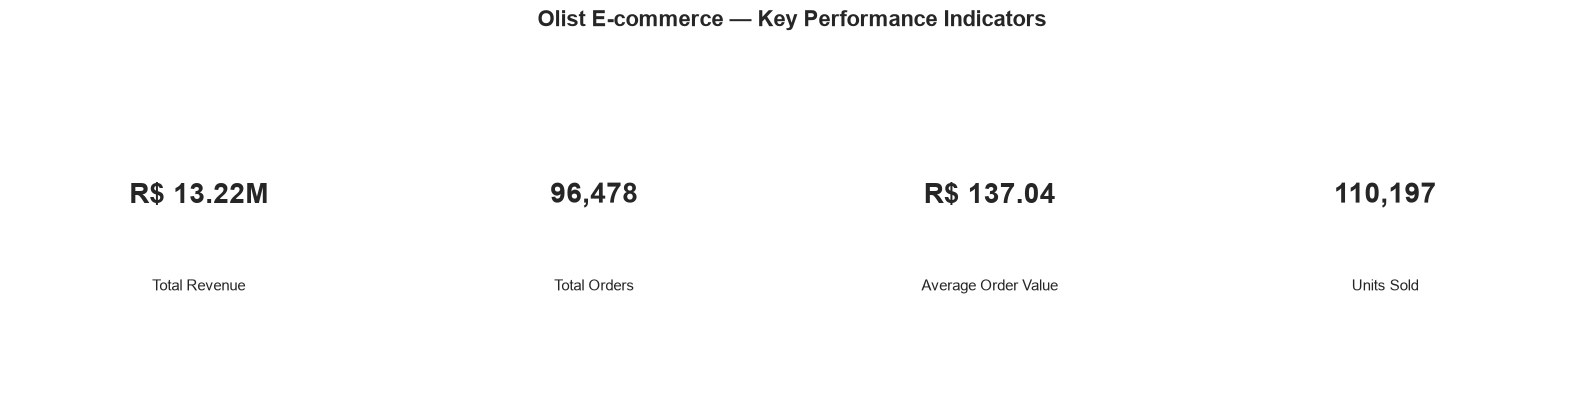

In [29]:
# KPI values from your completed analysis
total_revenue = 13221500
total_orders = 96478
average_order_value = 137.04
total_units_sold = 110197

# Create KPI cards
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

kpis = [
    ("Total Revenue", f"R$ {total_revenue / 1_000_000:.2f}M"),
    ("Total Orders", f"{total_orders:,}"),
    ("Average Order Value", f"R$ {average_order_value:.2f}"),
    ("Units Sold", f"{total_units_sold:,}")
]

for ax, (title, value) in zip(axes, kpis):
    ax.text(
        0.5, 0.58, value,
        ha="center", va="center",
        fontsize=20, fontweight="bold"
    )
    ax.text(
        0.5, 0.30, title,
        ha="center", va="center",
        fontsize=11
    )
    ax.set_axis_off()

plt.suptitle(
    "Olist E-commerce — Key Performance Indicators",
    fontsize=16, fontweight="bold"
)
plt.tight_layout()

OUTPUT_DIR = Path(r"G:\My Drive\data_science_week1_assignment\03_outputs\charts")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save the current chart
save_path = OUTPUT_DIR / "01_kpi_cards.png"

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

print("Chart saved:", save_path)

plt.show()

### 2. Line Chart — monthly revenue trend

In [12]:
# Attaching purchase date to the sales item records
# Check whether the purchase timestamp already exists
if "order_purchase_timestamp" not in sales_items.columns:
    sales_items = sales_items.merge(
        delivered_orders[["order_id", "order_purchase_timestamp"]],
        on="order_id",
        how="left",
        validate="many_to_one"
    )

# Extract year and month
sales_items["purchase_month"] = (
    sales_items["order_purchase_timestamp"].dt.to_period("M")
)

# Calculate monthly sales
monthly_sales = (
    sales_items.groupby("purchase_month")
    .agg(
        monthly_revenue=("price", "sum"),
        total_orders=("order_id", "nunique"),
        units_sold=("order_item_id", "count")
    )
    .reset_index()
    .sort_values("purchase_month")
)

# Format the month for display
monthly_sales["purchase_month"] = (
    monthly_sales["purchase_month"].astype(str)
)


Chart saved: G:\My Drive\data_science_week1_assignment\03_outputs\charts\02_monthly_revenue_trend.png


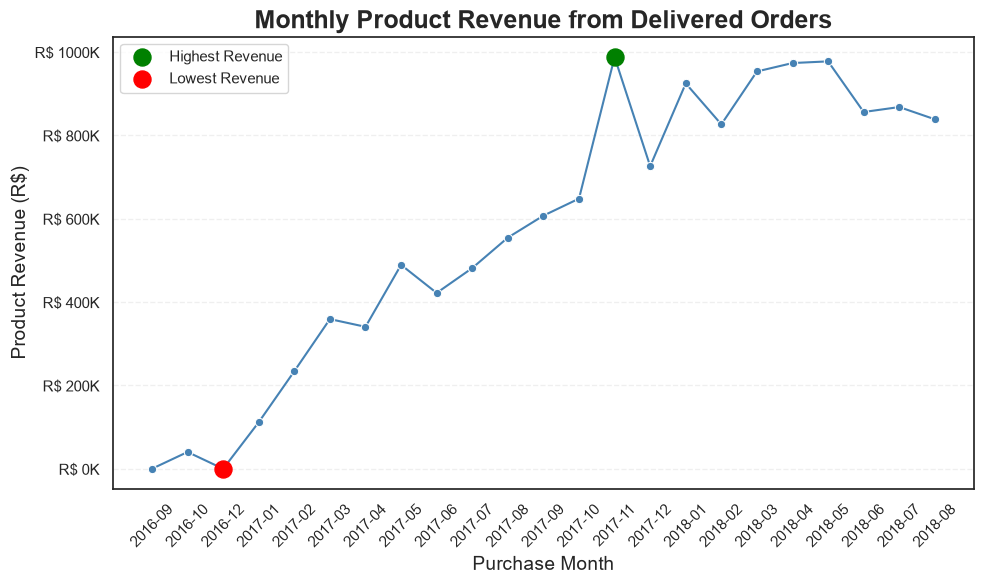

Highest revenue: 2017-11 (R$ 987,765.37)
Lowest revenue: 2016-12 (R$ 10.90)


In [30]:
# Visualizing monthly sales trends

# Find the months with the highest and lowest revenue
max_idx = monthly_sales["monthly_revenue"].idxmax()
min_idx = monthly_sales["monthly_revenue"].idxmin()

highest_month = monthly_sales.loc[max_idx]
lowest_month = monthly_sales.loc[min_idx]

plt.figure(figsize=(10, 6))

# Draw the monthly revenue trend
ax = sns.lineplot(
    data=monthly_sales,
    x="purchase_month",
    y="monthly_revenue",
    marker="o",
    color="steelblue"
)

# Highlight the highest value in green
plt.scatter(
    highest_month["purchase_month"],
    highest_month["monthly_revenue"],
    color="green",
    s=150,
    zorder=5,
    label="Highest Revenue"
)

# Highlight the lowest value in red
plt.scatter(
    lowest_month["purchase_month"],
    lowest_month["monthly_revenue"],
    color="red",
    s=150,
    zorder=5,
    label="Lowest Revenue"
)

plt.title(
    "Monthly Product Revenue from Delivered Orders",
    fontsize=18,
    fontweight="bold"
)
plt.xlabel("Purchase Month", fontsize=14)
plt.ylabel("Product Revenue (R$)", fontsize=14)

plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.3)

# Format y-axis in thousands (K)
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"R$ {x / 1_000:.0f}K")
)

plt.legend()
plt.tight_layout()

from pathlib import Path
import matplotlib.pyplot as plt

OUTPUT_DIR = Path(r"G:\My Drive\data_science_week1_assignment\03_outputs\charts")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save the current chart
save_path = OUTPUT_DIR / "02_monthly_revenue_trend.png"

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

print("Chart saved:", save_path)

plt.show()

# Print the highest and lowest revenue months
print(
    f"Highest revenue: {highest_month['purchase_month']} "
    f"(R$ {highest_month['monthly_revenue']:,.2f})"
)
print(
    f"Lowest revenue: {lowest_month['purchase_month']} "
    f"(R$ {lowest_month['monthly_revenue']:,.2f})"
)


### Key Business Insights

Monthly revenue peaked in November 2017 at approximately R$987,765. April and May 2018 also recorded strong revenue, each approaching R$1 million.

The very low revenue recorded in some early months may indicate incomplete data coverage. Therefore, these months should be interpreted cautiously when assessing overall sales trends.

**Business Recommendation:** Monitor monthly revenue to identify peak sales periods and support inventory planning and marketing decisions. Investigate the factors behind revenue peaks before attributing them to specific campaigns or seasonal effects.

### 3. Bar Chart — Top 10 Product Categories by Revenue

Chart saved: G:\My Drive\data_science_week1_assignment\03_outputs\charts\03_top_categories_by_revenue.png


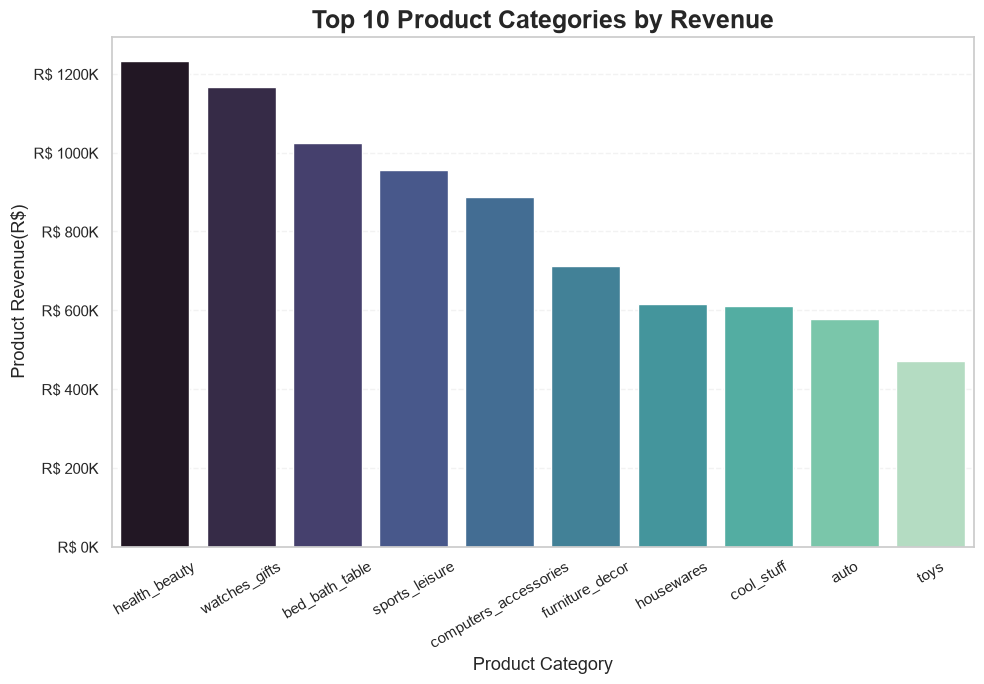

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

top_categories = (
    category_sales
    .sort_values("total_revenue", ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_categories,
    y="total_revenue",
    x="category_name_english",
    hue="category_name_english",
    palette="mako",
    legend=False
)

plt.title(
    "Top 10 Product Categories by Revenue",
    fontsize=18,
    fontweight="bold"
)
plt.xlabel("Product Category", fontsize=13)
plt.ylabel("Product Revenue(R$)", fontsize=13)

ax = plt.gca()
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"R$ {x / 1_000:.0f}K")
)

plt.xticks(rotation=30)
plt.grid(axis="y", linestyle="--", alpha=0.25)
plt.tight_layout()

from pathlib import Path
import matplotlib.pyplot as plt

OUTPUT_DIR = Path(r"G:\My Drive\data_science_week1_assignment\03_outputs\charts")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save the current chart
save_path = OUTPUT_DIR / "03_top_categories_by_revenue.png"

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

print("Chart saved:", save_path)
plt.show()


### Key Business Insights

Health & Beauty was the highest-revenue product category, followed by Watches & Gifts and Bed, Bath & Table. However, Bed, Bath & Table recorded the highest unit sales among the top 10 categories.

This difference between revenue and sales volume suggests that category performance depends on both the number of units sold and the revenue generated per unit.

**Business Recommendation:** Prioritize inventory planning for high-revenue categories while monitoring demand and sales volume to maintain product availability and identify growth opportunities.

### 4. Donut Chart — Customer Segmentation 
- What proportion of customers placed one delivered order versus multiple delivered orders?

In [15]:
# Merge the customer information

delivered_orders_customer = delivered_orders.merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

print("Total delivered orders:", len(delivered_orders_customer))
print(
    "Unique customers:",
    delivered_orders_customer["customer_unique_id"].nunique()
)
print(
    "Missing customer IDs:",
    delivered_orders_customer["customer_unique_id"].isna().sum()
)

# Count delivered orders per unique customer
customer_order_counts = (
    delivered_orders_customer
    .groupby("customer_unique_id")["order_id"]
    .nunique()
    .reset_index(name="order_count")
)

# Classify customers by purchase frequency
customer_order_counts["customer_segment"] = np.where(
    customer_order_counts["order_count"] == 1,
    "One-Time Customer",
    "Repeat Customer"
)

# Summarize each customer segment
customer_segment_summary = (
    customer_order_counts
    .groupby("customer_segment")
    .agg(
        total_customers=("customer_unique_id", "nunique"),
        total_orders=("order_count", "sum")
    )
    .reset_index()
)

# Calculate percentage of total customers
customer_segment_summary["customer_percentage"] = (
    customer_segment_summary["total_customers"]
    / customer_segment_summary["total_customers"].sum()
    * 100
)

Total delivered orders: 96478
Unique customers: 93358
Missing customer IDs: 0


Chart saved: G:\My Drive\data_science_week1_assignment\03_outputs\charts\04_customer_segments.png


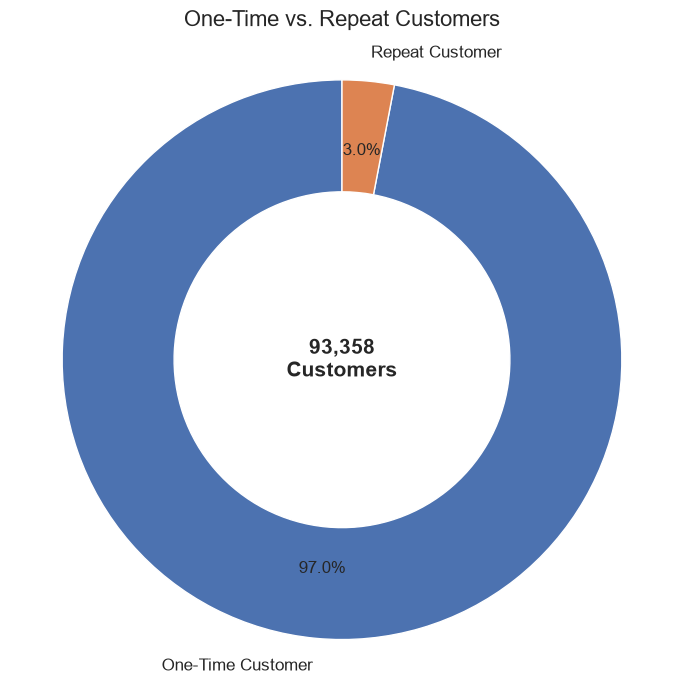

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Apply a Seaborn theme
sns.set_theme(style="white")

# Prepare chart data
labels = customer_segment_summary["customer_segment"]
sizes = customer_segment_summary["total_customers"]

# Create donut chart
fig, ax = plt.subplots(figsize=(7, 7))

wedges, texts, autotexts = ax.pie(
    sizes,
    labels=labels,
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.75,
    wedgeprops={"width": 0.4, "edgecolor": "white"},
    textprops={"fontsize": 12}
)

# Add total customers in the center
total_customers = sizes.sum()

ax.text(
    0, 0,
    f"{total_customers:,}\nCustomers",
    ha="center",
    va="center",
    fontsize=15,
    fontweight="bold"
)

plt.title("One-Time vs. Repeat Customers", fontsize=16, pad=20)
ax.axis("equal")
plt.tight_layout()
from pathlib import Path
import matplotlib.pyplot as plt

OUTPUT_DIR = Path(r"G:\My Drive\data_science_week1_assignment\03_outputs\charts")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save the current chart
save_path = OUTPUT_DIR / "04_customer_segments.png"

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

print("Chart saved:", save_path)
plt.show()

### Key Business Insights

The analysis identified 93,358 unique customers. Of these, 97% placed only one delivered order during the observation period, while approximately 3% placed multiple delivered orders.

This indicates that repeat purchasing was relatively uncommon within the available data. However, the results do not establish whether one-time customers will purchase again in the future.

**Business Recommendation:** Investigate opportunities to improve customer retention through personalized recommendations, loyalty programs, and targeted follow-up communication.

### 5. Histogram — Order Value Distribution
- How are order values distributed, and are most orders relatively low-value or high-value?

Chart saved: G:\My Drive\data_science_week1_assignment\03_outputs\charts\05_order_value_distribution.png


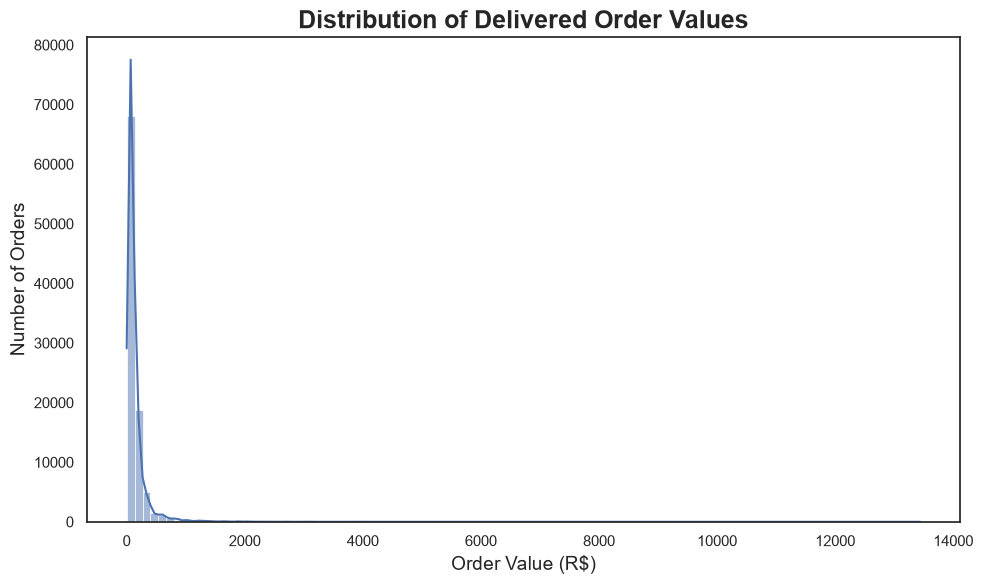

In [17]:
# Calculate product revenue per delivered order
order_value_data = delivered_items.groupby("order_id")["price"].sum()

plt.figure(figsize=(10, 6))

sns.histplot(
    order_value_data,
    bins=100,
    kde=True
)

plt.title("Distribution of Delivered Order Values",fontsize=18,fontweight="bold")
plt.xlabel("Order Value (R$)",fontsize=14)
plt.ylabel("Number of Orders",fontsize=14)
plt.tight_layout()

OUTPUT_DIR = Path(r"G:\My Drive\data_science_week1_assignment\03_outputs\charts")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save the current chart
save_path = OUTPUT_DIR / "05_order_value_distribution.png"

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

print("Chart saved:", save_path)

plt.show()

### Key Insight: Distribution of Delivered Order Values

The histogram shows a strongly right-skewed distribution, indicating that most delivered orders have relatively low values, while only a small proportion have very high values. The distribution has a long tail extending toward R$14,000, suggesting that high-value orders are much less common than lower-value orders.

**Business Recommendation:** The business could explore product bundling and targeted promotions to encourage customers to increase their spending per order.

### 6. Pie Chart — On-Time/Early vs. Late Delivery

In [18]:
# Selecting the columns required for delivery analysis
delivery_data = delivered_orders[
    [
        "order_id",
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
].copy()

# Removing records with missing dates required for this analysis
delivery_data = delivery_data.dropna(
    subset=[
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
).copy()

# Actual delivery duration from purchase to customer delivery
delivery_data["actual_delivery_days"] = (
    delivery_data["order_delivered_customer_date"]
    - delivery_data["order_purchase_timestamp"]
).dt.total_seconds() / (24 * 60 * 60)

# Estimated delivery duration from purchase to estimated delivery
delivery_data["estimated_delivery_days"] = (
    delivery_data["order_estimated_delivery_date"]
    - delivery_data["order_purchase_timestamp"]
).dt.total_seconds() / (24 * 60 * 60)

# Difference between actual and estimated delivery dates
delivery_data["delivery_delay_days"] = (
    delivery_data["order_delivered_customer_date"]
    - delivery_data["order_estimated_delivery_date"]
).dt.total_seconds() / (24 * 60 * 60)

# Classify delivery performance
delivery_data["delivery_status"] = np.where(
    delivery_data["delivery_delay_days"] > 0,
    "Late",
    "On Time or Early"
)

Chart saved: G:\My Drive\data_science_week1_assignment\03_outputs\charts\06_delivery_performance.png


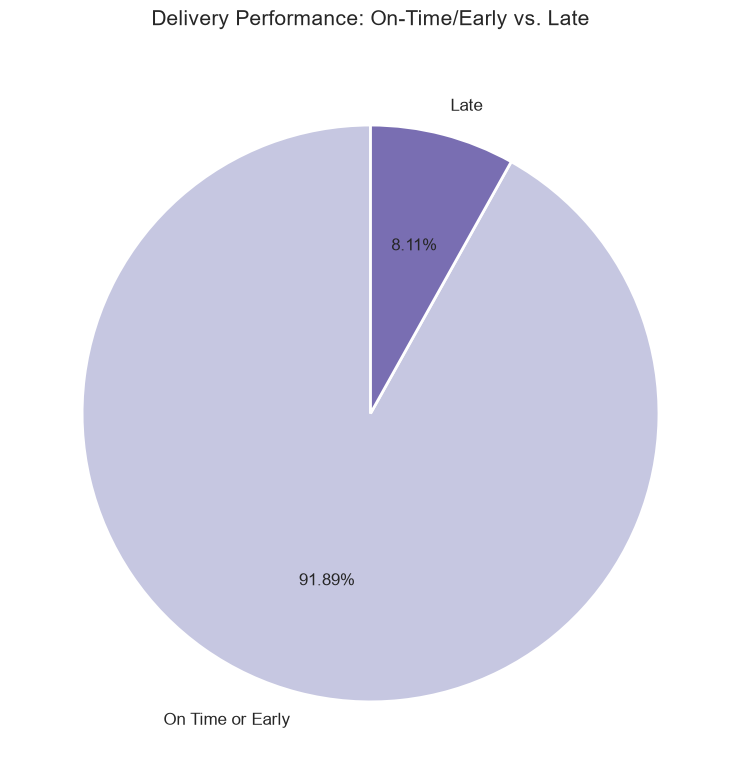

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns


# Count delivery outcomes
delivery_counts = delivery_data["delivery_status"].value_counts()

# Purple color palette
colors = sns.color_palette("Purples", n_colors=len(delivery_counts))

# Create pie chart
plt.figure(figsize=(8, 8))

plt.pie(
    delivery_counts.values,
    labels=delivery_counts.index,
    autopct="%1.2f%%",
    startangle=90,
    colors=colors,
    wedgeprops={"edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 12}
)

plt.title(
    "Delivery Performance: On-Time/Early vs. Late",
    fontsize=15,
    pad=20
)

plt.tight_layout()

from pathlib import Path
import matplotlib.pyplot as plt

OUTPUT_DIR = Path(r"G:\My Drive\data_science_week1_assignment\03_outputs\charts")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save the current chart
save_path = OUTPUT_DIR / "06_delivery_performance.png"

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

print("Chart saved:", save_path)
plt.show()

### Key Business Insights

Approximately 91.89% of delivered orders arrived on time or earlier than estimated, while 8.11% arrived late. Among late orders, the average delay was approximately 9.55 days.

Although most deliveries met or beat their estimated dates, late deliveries remain an area for operational improvement.

**Business Recommendation:** Analyze late deliveries by geographic region, seller, and order period to identify potential problem areas and improve delivery reliability.

### 7. Horizontal Bar Chart — Revenue by State
- Which Brazilian states/city contribute the most revenue?

In [20]:
# Merge delivered orders with customer information
delivered_orders_customer = delivered_orders.merge(
    customers[["customer_id", "customer_unique_id", "customer_state", "customer_city"]],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

# Attach order items to delivered orders
regional_sales = delivered_orders_customer.merge(
    order_items[["order_id", "price"]],
    on="order_id",
    how="inner",
    validate="one_to_many"
)

# Calculate revenue for each state
state_revenue = (
    regional_sales
    .groupby("customer_state", as_index=False)
    .agg(total_revenue=("price", "sum"))
)

# Select the top 10 states by revenue
top_states = (
    state_revenue
    .nlargest(10, "total_revenue")
    .sort_values("total_revenue", ascending=True)
)

In [21]:
# Brazilian state abbreviations and their full names
state_names = {
    "AC": "Acre",
    "AL": "Alagoas",
    "AP": "Amapá",
    "AM": "Amazonas",
    "BA": "Bahia",
    "CE": "Ceará",
    "DF": "Federal District",
    "ES": "Espírito Santo",
    "GO": "Goiás",
    "MA": "Maranhão",
    "MT": "Mato Grosso",
    "MS": "Mato Grosso do Sul",
    "MG": "Minas Gerais",
    "PA": "Pará",
    "PB": "Paraíba",
    "PR": "Paraná",
    "PE": "Pernambuco",
    "PI": "Piauí",
    "RJ": "Rio de Janeiro",
    "RN": "Rio Grande do Norte",
    "RS": "Rio Grande do Sul",
    "RO": "Rondônia",
    "RR": "Roraima",
    "SC": "Santa Catarina",
    "SP": "São Paulo",
    "SE": "Sergipe",
    "TO": "Tocantins"
}

# Add full state names to the DataFrame
top_states["state_name"] = top_states["customer_state"].map(state_names)

Chart saved: G:\My Drive\data_science_week1_assignment\03_outputs\charts\07_top_states_revenue.png


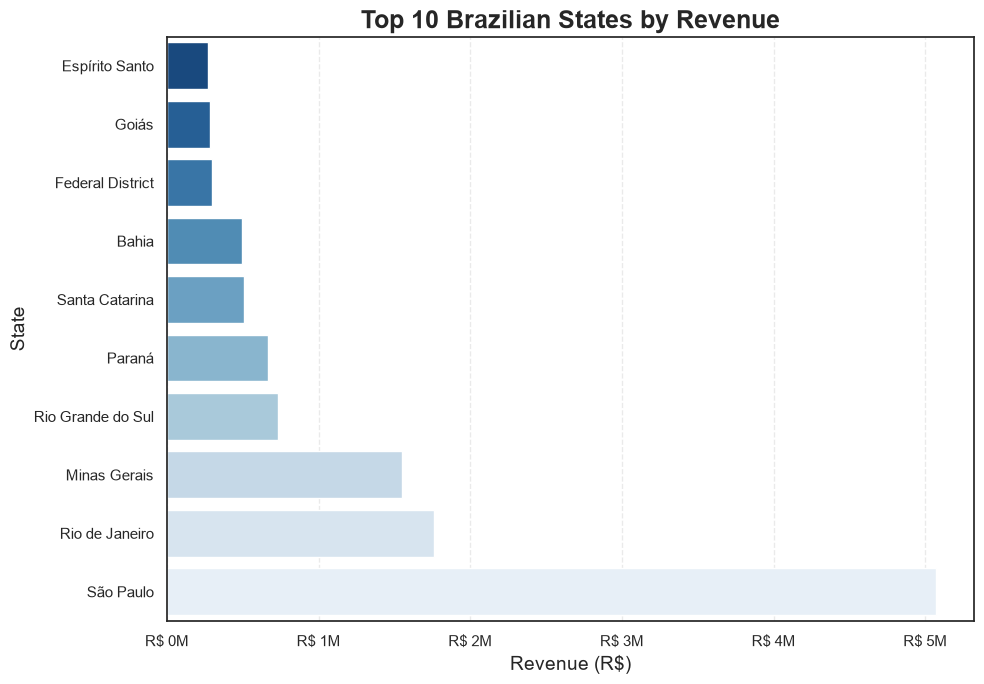

In [22]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_states,
    x="total_revenue",
    y="state_name",
    palette="Blues_r",
    hue="state_name",
    dodge=False
)

plt.title("Top 10 Brazilian States by Revenue", fontsize=18,fontweight="bold")
plt.xlabel("Revenue (R$)", fontsize=14)
plt.ylabel("State", fontsize=14)

ax = plt.gca()
ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"R$ {x / 1_000000:.0f}M")
)

plt.grid(True,axis="x",linestyle="--",alpha=0.4)
plt.tight_layout()

from pathlib import Path
import matplotlib.pyplot as plt

OUTPUT_DIR = Path(r"G:\My Drive\data_science_week1_assignment\03_outputs\charts")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save the current chart
save_path = OUTPUT_DIR / "07_top_states_revenue.png"

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

print("Chart saved:", save_path)

plt.show()

### Key Business Insights

São Paulo generated approximately R$5.07 million in revenue, representing 38.33% of total revenue. Rio de Janeiro and Minas Gerais followed, with the three leading states collectively contributing approximately 63.38% of total revenue.

This demonstrates that revenue is concentrated in a few major Brazilian markets.

**Business Recommendation:** Continue monitoring demand in the leading states while assessing opportunities in other regions. Expansion decisions should also consider logistics costs, competition, and profitability rather than revenue alone.

### 8. Heatmap — Monthly Sales Patterns
- How does revenue vary across months and years?

Chart saved: G:\My Drive\data_science_week1_assignment\03_outputs\charts\08_monthly_orders_heatmap.png


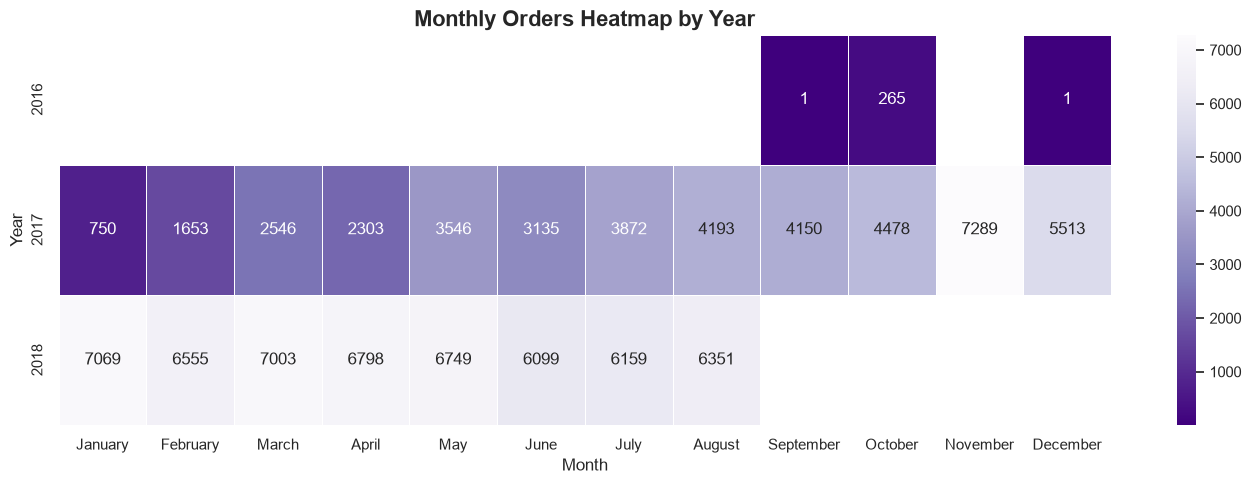

In [23]:
monthly_heatmap_data = monthly_sales.copy()

monthly_heatmap_data["purchase_month"] = pd.to_datetime(
    monthly_heatmap_data["purchase_month"]
)

monthly_heatmap_data["year"] = (
    monthly_heatmap_data["purchase_month"].dt.year
)

monthly_heatmap_data["month_name"] = (
    monthly_heatmap_data["purchase_month"].dt.month_name()
)

month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

heatmap_data = monthly_heatmap_data.pivot(
    index="year",
    columns="month_name",
    values="total_orders"
)

heatmap_data = heatmap_data.reindex(columns=month_order)

plt.figure(figsize=(14, 5))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".0f",
    cmap="Purples_r",
    linewidths=0.5
)

plt.title("Monthly Orders Heatmap by Year",fontsize=16,fontweight="bold")
plt.xlabel("Month")
plt.ylabel("Year")
plt.tight_layout()

from pathlib import Path
import matplotlib.pyplot as plt

OUTPUT_DIR = Path(r"G:\My Drive\data_science_week1_assignment\03_outputs\charts")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save the current chart
save_path = OUTPUT_DIR / "08_monthly_orders_heatmap.png"

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

print("Chart saved:", save_path)
plt.show()

### Key Insights: Distribution of Delivered Order Values

1. **Strong right-skewness:** The distribution is heavily concentrated at lower order values, with a long tail extending toward higher values.

2. **Most orders have relatively low values:** The high concentration near the lower end indicates that relatively low-value orders account for a large share of delivered orders.

3. **A small number of high-value orders:** A few orders have substantially higher values than the majority, extending to approximately R$14,000.

4. **Impact of outliers:** These high-value orders stretch the distribution and make it difficult to examine the typical order-value range in detail.

**Business Recommendation:** Analyze the typical order-value range separately from high-value orders. The business could also investigate strategies such as product bundling and targeted promotions to encourage customers to purchase more per order, while evaluating their impact on profitability.

### 9. Box Plot — Delivery Time Distribution
- How much does actual delivery time vary between orders?

In [24]:
# Selecting the columns required for delivery analysis
delivery_data = delivered_orders[
    [
        "order_id",
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
].copy()

# Removing records with missing dates required for this analysis
delivery_data = delivery_data.dropna(
    subset=[
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
).copy()

In [25]:
# Actual delivery duration from purchase to customer delivery
delivery_data["actual_delivery_days"] = (
    delivery_data["order_delivered_customer_date"]
    - delivery_data["order_purchase_timestamp"]
).dt.total_seconds() / (24 * 60 * 60)

# Estimated delivery duration from purchase to estimated delivery
delivery_data["estimated_delivery_days"] = (
    delivery_data["order_estimated_delivery_date"]
    - delivery_data["order_purchase_timestamp"]
).dt.total_seconds() / (24 * 60 * 60)

# Difference between actual and estimated delivery dates
delivery_data["delivery_delay_days"] = (
    delivery_data["order_delivered_customer_date"]
    - delivery_data["order_estimated_delivery_date"]
).dt.total_seconds() / (24 * 60 * 60)

# Classify delivery performance
delivery_data["delivery_status"] = np.where(
    delivery_data["delivery_delay_days"] > 0,
    "Late",
    "On Time or Early"
)

Chart saved: G:\My Drive\data_science_week1_assignment\03_outputs\charts\09_delivery_time_distribution.png


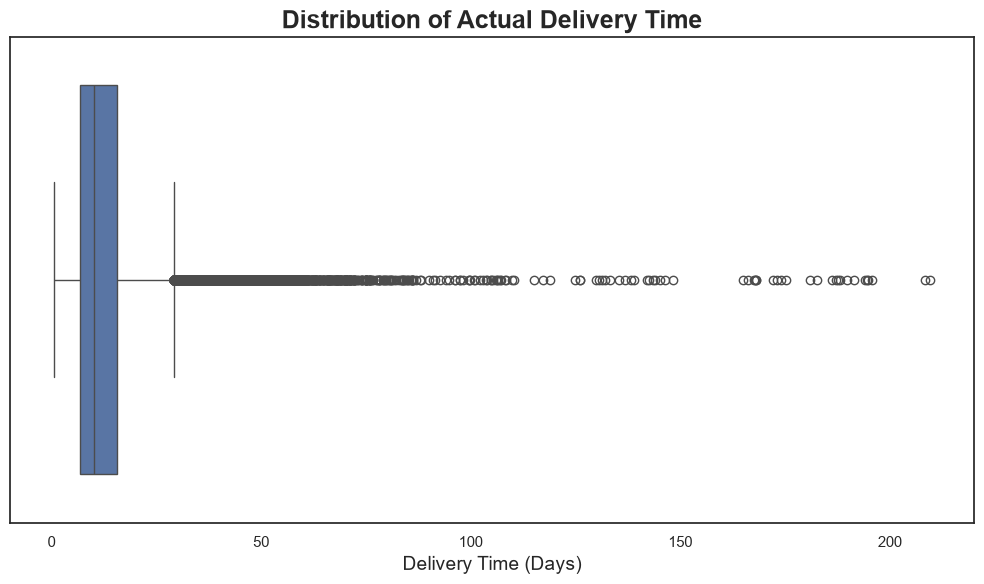

In [26]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    x=delivery_data["actual_delivery_days"]
)

plt.title("Distribution of Actual Delivery Time",fontsize=18,fontweight="bold")
plt.xlabel("Delivery Time (Days)",fontsize=14)

plt.tight_layout()

from pathlib import Path
import matplotlib.pyplot as plt

OUTPUT_DIR = Path(r"G:\My Drive\data_science_week1_assignment\03_outputs\charts")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save the current chart
save_path = OUTPUT_DIR / "09_delivery_time_distribution.png"

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

print("Chart saved:", save_path)
plt.show()

### Key Business Insights

The delivery analysis recorded an average actual delivery time of approximately 12.56 days, compared with an average estimated delivery time of 23.74 days.

The box plot provides additional detail about the distribution of delivery durations, including typical delivery times, variability, and unusually long deliveries.

**Business Recommendation:** Investigate unusually long delivery times to identify potential operational bottlenecks. Compare the distribution across states, sellers, or periods to determine whether certain groups experience longer delivery times.

### 10. Scatter Plot — Product Price vs Freight Cost
- Is there a relationship between product price and freight cost?

Chart saved: G:\My Drive\data_science_week1_assignment\03_outputs\charts\10_product_price_vs_freight_cost.png


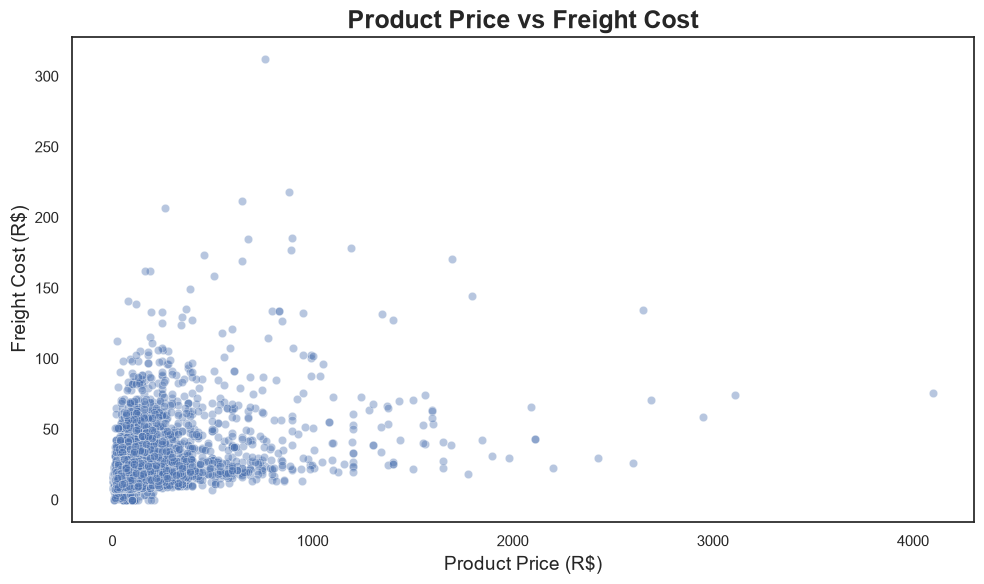

In [31]:
# Use a sample for a clearer plot if the dataset is large
scatter_data = delivered_items[
    ["price", "freight_value"]
].dropna()

if len(scatter_data) > 10000:
    scatter_data = scatter_data.sample(
        n=10000,
        random_state=42
    )

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=scatter_data,
    x="price",
    y="freight_value",
    alpha=0.4
)

plt.title("Product Price vs Freight Cost",fontsize=18,fontweight="bold")
plt.xlabel("Product Price (R$)",fontsize=14)
plt.ylabel("Freight Cost (R$)",fontsize=14)
plt.tight_layout()

OUTPUT_DIR = Path(r"G:\My Drive\data_science_week1_assignment\03_outputs\charts") 
OUTPUT_DIR.mkdir(parents=True, exist_ok=True) 

# Save the current chart 
save_path = OUTPUT_DIR / "10_product_price_vs_freight_cost.png" 
plt.savefig( save_path, dpi=300, bbox_inches="tight", facecolor="white" ) 
print("Chart saved:", save_path)

plt.show()

### Key Insights: Product Price vs Freight Cost

1. **Concentration of low-priced products:** Most products are clustered in the lower price range, with freight costs generally below R$100.

2. **No clear linear relationship:** The scatter plot does not show a strong, obvious relationship between product price and freight cost. Higher-priced products do not necessarily have higher freight costs.

3. **Presence of outliers:** A small number of products have unusually high prices or freight costs. These cases may warrant further investigation to understand their shipping requirements.

4. **Further analysis opportunities:** Product weight, dimensions, and delivery distance could help explain variations in freight costs.

**Business Recommendation:** Investigate products with unusually high freight costs and compare shipping expenses across product weights, dimensions, and customer regions to identify potential opportunities to improve shipping efficiency.